<a href="https://colab.research.google.com/github/jostina/Netflix-Dataset/blob/main/Task_6_Data_Science_Business_Insights_Dashboard_Using_Netflix_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset overview

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("/content/netflix_titles_cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,date_added_year,date_added_month,date_added_month_name,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,September,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,September,1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,September,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,September,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,September,125,min


Complete data analysis (EDA)

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


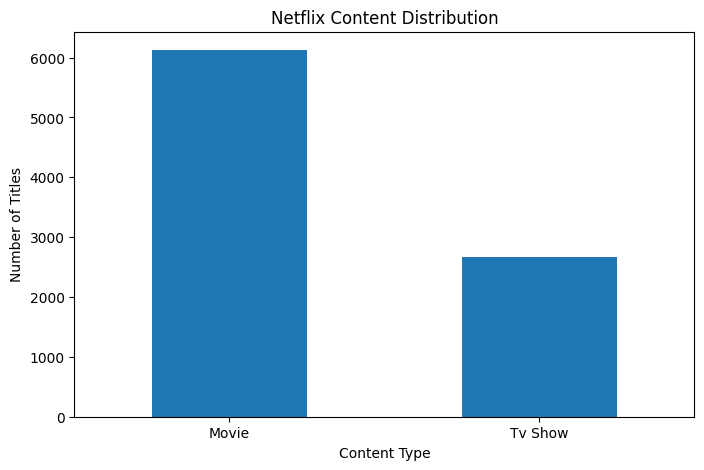

In [4]:
content_counts = df["type"].value_counts()

print(content_counts)

content_counts.plot(
    kind="bar",
    title="Netflix Content Distribution",
    xlabel="Content Type",
    ylabel="Number of Titles",
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.show()

Content production trends

In [5]:
yearly_content = (
    df.groupby(["release_year", "type"])
      .size()
      .reset_index(name="total_titles")
)

fig = px.line(
    yearly_content,
    x="release_year",
    y="total_titles",
    color="type",
    title="Netflix Content Release Trends",
    markers=True
)

fig.show()

Most popular genres in the catalogue

In [6]:
genre_df = df.assign(
    genre=df["listed_in"].str.split(", ")
).explode("genre")

top_genres = (
    genre_df["genre"]
    .value_counts()
    .head(10)
    .reset_index()
)

top_genres.columns = ["genre", "total_titles"]

fig = px.bar(
    top_genres,
    x="total_titles",
    y="genre",
    orientation="h",
    title="Top 10 Netflix Genres",
    color="total_titles"
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

Geographic content distribution

In [7]:
country_df = df.assign(
    country=df["country"].str.split(", ")
).explode("country")

country_df["country"] = country_df["country"].str.strip()

top_countries = (
    country_df["country"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

top_countries.columns = ["country", "total_titles"]

fig = px.bar(
    top_countries,
    x="country",
    y="total_titles",
    title="Top 10 Countries by Netflix Content",
    color="total_titles"
)

fig.show()

Movie duration analysis

In [8]:
movies = df[df["type"] == "Movie"].copy()

movies["duration_minutes"] = (
    movies["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

fig = px.histogram(
    movies,
    x="duration_minutes",
    nbins=30,
    title="Distribution of Netflix Movie Durations",
    labels={"duration_minutes": "Duration (minutes)"}
)

fig.show()

Develop predictive models
Model 1: Classification

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create simplified categorical features
model_df = df.copy()

model_df["primary_genre"] = (
    model_df["listed_in"].str.split(", ").str[0]
)

model_df["primary_country"] = (
    model_df["country"].str.split(", ").str[0]
)

features = [
    "release_year",
    "rating",
    "primary_genre",
    "primary_country"
]

X = model_df[features]
y = model_df["type"]

categorical_features = [
    "rating",
    "primary_genre",
    "primary_country"
]

numeric_features = ["release_year"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="constant",
                    fill_value="Unknown"
                )),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categorical_features
        ),
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median"
                )),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        )
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 1.0
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



Evaluate the classification model

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

fig = px.imshow(
    cm,
    text_auto=True,
    x=model.classes_,
    y=model.classes_,
    title="Netflix Content Classification Confusion Matrix",
    labels={
        "x": "Predicted Content Type",
        "y": "Actual Content Type",
        "color": "Count"
    }
)

fig.show()

Model 2: K-Means content segmentation
First, create features for clustering.

In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

cluster_df = df.copy()

cluster_df["primary_genre"] = (
    cluster_df["listed_in"].str.split(", ").str[0]
)

cluster_df["duration_value"] = pd.to_numeric(
    cluster_df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

cluster_features = cluster_df[
    ["release_year", "duration_value"]
].copy()

cluster_features = cluster_features.fillna(
    cluster_features.median()
)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(cluster_features)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_df["cluster"] = kmeans.fit_predict(X_scaled)

print(cluster_df.groupby("cluster").agg(
    total_titles=("show_id", "count"),
    average_release_year=("release_year", "mean"),
    average_duration=("duration_value", "mean")
))

         total_titles  average_release_year  average_duration
cluster                                                      
0                2911           2017.064583          4.803847
1                1087           2004.573137        114.295308
2                4500           2016.978889         99.044444
3                 292           1978.147260        105.482877


Visualize the segments:

In [12]:
fig = px.scatter(
    cluster_df,
    x="release_year",
    y="duration_value",
    color="cluster",
    hover_data=["title", "type", "primary_genre"],
    title="Netflix Content Segmentation Using K-Means"
)

fig.show()

Create an interactive business dashboard
I will use Streamlit + Plotly

In [13]:
pip install streamlit pandas numpy plotly scikit-learn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 25.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [14]:

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import joblib

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Netflix Business Insights",
    page_icon="🎬",
    layout="wide"
)

# --------------------------------------------------
# 2. LOAD DATA
# --------------------------------------------------

@st.cache_data
def load_data():
    data = pd.read_csv("/content/netflix_titles_cleaned.csv")
    return data

df = load_data()

# --------------------------------------------------
# 3. DASHBOARD HEADER
# --------------------------------------------------

st.title("🎬 Netflix Business Insights Dashboard")

st.markdown(
    """
    Explore Netflix content trends, geographic distribution,
    genre patterns and business opportunities using data science.
    """
)

st.divider()

# --------------------------------------------------
# 4. SIDEBAR FILTERS
# --------------------------------------------------

st.sidebar.header("Dashboard Filters")

content_type = st.sidebar.multiselect(
    "Content Type",
    options=sorted(df["type"].dropna().unique()),
    default=sorted(df["type"].dropna().unique())
)

min_year = int(df["release_year"].min())
max_year = int(df["release_year"].max())

year_range = st.sidebar.slider(
    "Release Year",
    min_year,
    max_year,
    (min_year, max_year)
)

# Apply filters
filtered_df = df[
    (df["type"].isin(content_type)) &
    (df["release_year"].between(*year_range))
].copy()

# --------------------------------------------------
# 5. KPI METRICS
# --------------------------------------------------

st.subheader("📊 Catalogue Overview")

total_titles = len(filtered_df)

total_movies = (
    filtered_df["type"] == "Movie"
).sum()

total_shows = (
    filtered_df["type"] == "TV Show"
).sum()

total_countries = (
    filtered_df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .nunique()
)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Titles", f"{total_titles:,}")
col2.metric("Movies", f"{total_movies:,}")
col3.metric("TV Shows", f"{total_shows:,}")
col4.metric("Countries", f"{total_countries:,}")

st.divider()

# --------------------------------------------------
# 6. CONTENT DISTRIBUTION
# --------------------------------------------------

st.subheader("📺 Content Distribution")

left, right = st.columns(2)

with left:

    type_counts = filtered_df["type"].value_counts()

    fig = px.pie(
        values=type_counts.values,
        names=type_counts.index,
        hole=0.45,
        title="Movies vs TV Shows"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

with right:

    yearly = (
        filtered_df.groupby("release_year")
        .size()
        .reset_index(name="titles")
    )

    fig = px.line(
        yearly,
        x="release_year",
        y="titles",
        markers=True,
        title="Titles Released by Year"
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

# --------------------------------------------------
# 7. GENRE ANALYSIS
# --------------------------------------------------

st.subheader("🎭 Genre Analysis")

genre_data = filtered_df.assign(
    genre=filtered_df["listed_in"].str.split(", ")
).explode("genre")

genre_counts = (
    genre_data["genre"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

genre_counts.columns = ["Genre", "Titles"]

fig = px.bar(
    genre_counts.sort_values("Titles"),
    x="Titles",
    y="Genre",
    orientation="h",
    title="Top 10 Netflix Genres",
    color="Titles"
)

st.plotly_chart(
    fig,
    use_container_width=True
)

# --------------------------------------------------
# 8. GEOGRAPHIC ANALYSIS
# --------------------------------------------------

st.subheader("🌍 Geographic Distribution")

country_data = filtered_df.assign(
    country=filtered_df["country"].str.split(", ")
).explode("country")

country_counts = (
    country_data["country"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

country_counts.columns = ["Country", "Titles"]

fig = px.bar(
    country_counts.sort_values("Titles"),
    x="Titles",
    y="Country",
    orientation="h",
    title="Top 10 Content-Producing Countries",
    color="Titles"
)

st.plotly_chart(
    fig,
    use_container_width=True
)

# --------------------------------------------------
# 9. DATASET EXPLORER
# --------------------------------------------------

st.subheader("🔎 Explore Netflix Catalogue")

search = st.text_input("Search for a title")

explorer_df = filtered_df.copy()

if search:
    explorer_df = explorer_df[
        explorer_df["title"].str.contains(
            search,
            case=False,
            na=False
        )
    ]

display_columns = [
    "title",
    "type",
    "release_year",
    "country",
    "rating",
    "listed_in"
]

st.dataframe(
    explorer_df[display_columns],
    use_container_width=True,
    hide_index=True
)

# Download filtered data
csv = explorer_df.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download Filtered Dataset",
    data=csv,
    file_name="netflix_filtered_data.csv",
    mime="text/csv"
)

# --------------------------------------------------
# 10. FOOTER
# --------------------------------------------------

st.divider()

st.caption(
    "Netflix Content Analytics | Advanced Data Science Project"
)


2026-11-07 12:10:44.073 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:10:44.079 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-07 12:10:44.086 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-07 12:10:44.091 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:10:44.313 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:10:45.098 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-07 12:10:45.100 Thread 'MainThread': mi

DeltaGenerator()

In [15]:
!pip install -q streamlit plotly pyngrok

In [16]:
!streamlit run app.py &>/content/streamlit.log &

In [24]:
!rm -f /root/.config/ngrok/ngrok.yml

In [25]:
!rm -f /root/.config/ngrok/ngrok.yml

In [30]:
from pyngrok import ngrok

# Stop existing ngrok processes
ngrok.kill()

# Remove the old configuration
!rm -f /root/.config/ngrok/ngrok.yml

print("Old ngrok configuration removed.")

Old ngrok configuration removed.


In [32]:
from pyngrok import ngrok
from getpass import getpass

# Enter your actual token when prompted
token = getpass("Enter your ngrok authtoken: ")

# Save the token
ngrok.set_auth_token(token)

print("Ngrok token configured.")

Enter your ngrok authtoken: ··········
Ngrok token configured.


In [33]:
!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [35]:
!pip install -q --upgrade streamlit pyngrok

In [36]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)

print("Netflix Business Insights Dashboard:")
print(public_url)

ERROR:pyngrok.process.ngrok:t=2026-11-07T12:30:49+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"
ERROR:pyngrok.process.ngrok:t=2026-11-07T12:30:49+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n.

In [37]:
from getpass import getpass
from pyngrok import ngrok
from pyngrok.conf import PyngrokConfig

# Stop any existing ngrok process
ngrok.kill()

# Enter the token from your ngrok dashboard
token = getpass("Paste your actual ngrok AUTHTOKEN: ").strip()

# Check that something was entered without displaying the token
if not token:
    raise ValueError("No token was entered.")

print("Token entered. Character count:", len(token))

# Create a configuration using this token directly
config = PyngrokConfig(auth_token=token)

print("Ngrok configuration created.")

Paste your actual ngrok AUTHTOKEN: ··········
Token entered. Character count: 49
Ngrok configuration created.


In [38]:
from pyngrok import ngrok

public_url = ngrok.connect(
    addr=8501,
    pyngrok_config=config
)

print("Netflix Business Insights Dashboard:")
print(public_url)

Netflix Business Insights Dashboard:
NgrokTunnel: "https://flaring-jockstrap-paprika.ngrok-free.dev" -> "http://localhost:8501"


In [39]:
!ps aux | grep streamlit

root        9690  0.0  0.0   7344  3504 ?        S    12:35   0:00 /bin/bash -c ps aux | grep streamlit
root        9692  0.0  0.0   6548  2296 ?        S    12:35   0:00 grep streamlit


In [40]:
!cat /content/streamlit.log

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: app.py


In [41]:
!pkill -f "streamlit run"

In [42]:
!streamlit run app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

In [45]:
import os

print("Current directory:", os.getcwd())
print("Files available:", os.listdir())

Current directory: /content
Files available: ['.config', 'netflix_titles_cleaned.csv', 'streamlit.log', '.ipynb_checkpoints', 'sample_data']


In [46]:
%%writefile /content/app.py

Writing /content/app.py


In [47]:
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Netflix Business Insights",
    page_icon="🎬",
    layout="wide"
)

@st.cache_data
def load_data():
    return pd.read_csv("/content/netflix_titles_cleaned.csv")

df = load_data()

st.title("🎬 Netflix Business Insights Dashboard")
st.write("Explore Netflix content trends and business opportunities.")

# Sidebar filters
st.sidebar.header("Dashboard Filters")

content_type = st.sidebar.multiselect(
    "Content Type",
    options=sorted(df["type"].dropna().unique()),
    default=sorted(df["type"].dropna().unique())
)

min_year = int(df["release_year"].min())
max_year = int(df["release_year"].max())

year_range = st.sidebar.slider(
    "Release Year",
    min_year,
    max_year,
    (min_year, max_year)
)

filtered_df = df[
    df["type"].isin(content_type) &
    df["release_year"].between(*year_range)
].copy()

# KPIs
st.subheader("Catalogue Overview")

total_countries = (
    filtered_df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .nunique()
)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Titles", f"{len(filtered_df):,}")
col2.metric("Movies", f"{(filtered_df['type'] == 'Movie').sum():,}")
col3.metric("TV Shows", f"{(filtered_df['type'] == 'TV Show').sum():,}")
col4.metric("Countries", f"{total_countries:,}")

st.divider()

# Content distribution
st.subheader("Content Distribution")

col1, col2 = st.columns(2)

with col1:
    counts = filtered_df["type"].value_counts()

    fig = px.pie(
        values=counts.values,
        names=counts.index,
        hole=0.45,
        title="Movies vs TV Shows"
    )

    st.plotly_chart(fig, use_container_width=True)

with col2:
    yearly = (
        filtered_df.groupby("release_year")
        .size()
        .reset_index(name="titles")
    )

    fig = px.line(
        yearly,
        x="release_year",
        y="titles",
        markers=True,
        title="Titles by Release Year"
    )

    st.plotly_chart(fig, use_container_width=True)

# Genre analysis
st.subheader("Genre Analysis")

genre_data = filtered_df.assign(
    genre=filtered_df["listed_in"].str.split(", ")
).explode("genre")

genre_counts = (
    genre_data["genre"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

genre_counts.columns = ["Genre", "Titles"]

fig = px.bar(
    genre_counts.sort_values("Titles"),
    x="Titles",
    y="Genre",
    orientation="h",
    title="Top 10 Genres"
)

st.plotly_chart(fig, use_container_width=True)

# Geographic analysis
st.subheader("Geographic Analysis")

country_data = filtered_df.assign(
    country=filtered_df["country"].str.split(", ")
).explode("country")

country_counts = (
    country_data["country"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

country_counts.columns = ["Country", "Titles"]

fig = px.bar(
    country_counts.sort_values("Titles"),
    x="Titles",
    y="Country",
    orientation="h",
    title="Top 10 Content-Producing Countries"
)

st.plotly_chart(fig, use_container_width=True)

# Search
st.subheader("Explore Netflix Catalogue")

search = st.text_input("Search for a title")

explorer_df = filtered_df.copy()

if search:
    explorer_df = explorer_df[
        explorer_df["title"].str.contains(
            search,
            case=False,
            na=False
        )
    ]

st.dataframe(explorer_df, use_container_width=True)

st.caption("Netflix Content Analytics | Advanced Data Science Project")

2026-11-07 12:44:04.862 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:44:04.866 No runtime found, using MemoryCacheStorageManager
2026-11-07 12:44:04.868 No runtime found, using MemoryCacheStorageManager
2026-11-07 12:44:04.872 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:44:04.946 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:44:04.946 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:44:04.951 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:44:04.955 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-07 12:44:04.959 Thread 'MainThread': missing ScriptRunContext! This warning can be ignor

DeltaGenerator()

In [48]:
import os

print(os.listdir("/content"))
print("app.py exists:", os.path.exists("/content/app.py"))

['.config', 'app.py', 'netflix_titles_cleaned.csv', 'streamlit.log', '.ipynb_checkpoints', 'sample_data']
app.py exists: True


In [49]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [50]:
!sleep 5
!tail -20 /content/streamlit.log



2026-11-07 12:44:58.224 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.23.116.176:8501



In [51]:
import requests

response = requests.get(
    "http://127.0.0.1:8501/_stcore/health"
)

print(response.status_code)
print(response.text)

200
ok


In [54]:
from pyngrok import ngrok

ngrok.kill()

In [55]:
from pyngrok import ngrok

public_url = ngrok.connect(
    addr=8501,
    proto="http",
    pyngrok_config=config
)

print("Your Netflix Business Insights Dashboard:")
print(public_url)

Your Netflix Business Insights Dashboard:
NgrokTunnel: "https://flaring-jockstrap-paprika.ngrok-free.dev" -> "http://localhost:8501"


In [56]:
import requests

url = "http://127.0.0.1:8501/_stcore/health"

try:
    response = requests.get(url, timeout=10)
    print("Status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Connection error:", e)

Status: 200
Response: ok


In [57]:
!tail -50 /content/streamlit.log



2026-11-07 12:44:58.224 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.23.116.176:8501



In [58]:
import requests

response = requests.get("http://127.0.0.1:8501")

print("HTTP status:", response.status_code)
print("HTML length:", len(response.text))
print(response.text[:500])

HTTP status: 200
HTML length: 7863
<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or im


In [59]:
!tail -80 /content/streamlit.log



2026-11-07 12:44:58.224 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.23.116.176:8501



In [60]:
with open("/content/app.py", "r") as file:
    code = file.read()

print("App file size:", len(code))
print("Dashboard title exists:", "Netflix Business Insights Dashboard" in code)
print("Dataset path exists:", "/content/netflix_titles_cleaned.csv" in code)

App file size: 1
Dashboard title exists: False
Dataset path exists: False


In [61]:

%%writefile /content/app.py

import streamlit as st
import pandas as pd
import plotly.express as px

# Page configuration
st.set_page_config(
    page_title="Netflix Business Insights",
    page_icon="🎬",
    layout="wide"
)

# Load dataset
@st.cache_data
def load_data():
    return pd.read_csv("/content/netflix_titles_cleaned.csv")

df = load_data()

# Dashboard heading
st.title("🎬 Netflix Business Insights Dashboard")
st.markdown(
    "Explore Netflix content trends, geographic distribution "
    "and business opportunities using data science."
)

st.divider()

# Sidebar filters
st.sidebar.header("Dashboard Filters")

content_type = st.sidebar.multiselect(
    "Content Type",
    options=sorted(df["type"].dropna().unique()),
    default=sorted(df["type"].dropna().unique())
)

min_year = int(df["release_year"].min())
max_year = int(df["release_year"].max())

year_range = st.sidebar.slider(
    "Release Year",
    min_year,
    max_year,
    (min_year, max_year)
)

filtered_df = df[
    df["type"].isin(content_type) &
    df["release_year"].between(*year_range)
].copy()

# KPI metrics
st.subheader("📊 Catalogue Overview")

total_countries = (
    filtered_df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .nunique()
)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Titles", f"{len(filtered_df):,}")
col2.metric(
    "Movies",
    f"{(filtered_df['type'] == 'Movie').sum():,}"
)
col3.metric(
    "TV Shows",
    f"{(filtered_df['type'] == 'TV Show').sum():,}"
)
col4.metric("Countries", f"{total_countries:,}")

st.divider()

# Content distribution
st.subheader("📺 Content Distribution")

left, right = st.columns(2)

with left:
    type_counts = filtered_df["type"].value_counts()

    fig = px.pie(
        values=type_counts.values,
        names=type_counts.index,
        hole=0.45,
        title="Movies vs TV Shows"
    )

    st.plotly_chart(fig, use_container_width=True)

with right:
    yearly = (
        filtered_df.groupby("release_year")
        .size()
        .reset_index(name="titles")
    )

    fig = px.line(
        yearly,
        x="release_year",
        y="titles",
        markers=True,
        title="Titles by Release Year"
    )

    st.plotly_chart(fig, use_container_width=True)

# Genre analysis
st.subheader("🎭 Genre Analysis")

genre_data = filtered_df.assign(
    genre=filtered_df["listed_in"].str.split(", ")
).explode("genre")

genre_counts = (
    genre_data["genre"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

genre_counts.columns = ["Genre", "Titles"]

fig = px.bar(
    genre_counts.sort_values("Titles"),
    x="Titles",
    y="Genre",
    orientation="h",
    title="Top 10 Netflix Genres"
)

st.plotly_chart(fig, use_container_width=True)

# Geographic analysis
st.subheader("🌍 Geographic Analysis")

country_data = filtered_df.assign(
    country=filtered_df["country"].str.split(", ")
).explode("country")

country_counts = (
    country_data["country"]
    .dropna()
    .value_counts()
    .head(10)
    .reset_index()
)

country_counts.columns = ["Country", "Titles"]

fig = px.bar(
    country_counts.sort_values("Titles"),
    x="Titles",
    y="Country",
    orientation="h",
    title="Top 10 Content-Producing Countries"
)

st.plotly_chart(fig, use_container_width=True)

# Catalogue explorer
st.subheader("🔎 Explore Netflix Catalogue")

search = st.text_input("Search for a title")

explorer_df = filtered_df.copy()

if search:
    explorer_df = explorer_df[
        explorer_df["title"].str.contains(
            search,
            case=False,
            na=False
        )
    ]

display_columns = [
    "title",
    "type",
    "release_year",
    "country",
    "rating",
    "listed_in"
]

st.dataframe(
    explorer_df[display_columns],
    use_container_width=True,
    hide_index=True
)

# Download filtered data
csv = explorer_df.to_csv(index=False).encode("utf-8")

st.download_button(
    "Download Filtered Dataset",
    data=csv,
    file_name="netflix_filtered_data.csv",
    mime="text/csv"
)

st.divider()

st.caption(
    "Netflix Content Analytics | Advanced Data Science Project"
)


Overwriting /content/app.py


In [62]:
import os

print("File exists:", os.path.exists("/content/app.py"))
print("File size:", os.path.getsize("/content/app.py"))

with open("/content/app.py", "r") as file:
    code = file.read()

print("Dashboard title exists:",
      "Netflix Business Insights Dashboard" in code)

print("Dataset path exists:",
      "/content/netflix_titles_cleaned.csv" in code)

File exists: True
File size: 4129
Dashboard title exists: True
Dataset path exists: True


In [63]:
!pkill -f "streamlit run"

In [67]:
!streamlit run /content/app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    > /content/streamlit.log 2>&1 &